# TourShield - regressão linear simples e múltipla (TP3)
Helena Gomes | 25/10/2026
Objetivo didático: estimar n_words (número de palavras) a partir de atributos do texto.
A tarefa de negócio continua sendo classificação multiclasse de intenção, não regressão.
Fonte: CLINC150, Larson et al. (2019), CC BY 3.0; recorte e limpeza do TP1 preservados.

In [1]:
from pathlib import Path
import json
import re
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd()
if not (ROOT / "data" / "tourshield_clean.csv").exists():
    ROOT = ROOT.parent
OUT = ROOT / "reports" / "tp3"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ROOT / "data" / "tourshield_clean.csv", dtype={"message": "string", "intent": "string", "split": "string"})
assert df["message"].notna().all() and df["sample_id"].is_unique
print("Shape:", df.shape)
print("Splits:\n", df["split"].value_counts())

Shape: (3000, 6)
Splits:
 split
train    2000
test      600
val       400
Name: count, dtype: Int64


## Alvo e pré-processamento
Alvo: n_words, calculado por separação por espaços. Atributos fixos por mensagem:
n_chars, n_digits, n_punctuation e uppercase_ratio. Não usar intent/split/sample_id como
feature. Não usar n_words nem mean_word_length em X (reconstruiriam o alvo diretamente).
Caracteres ainda têm relação estrutural com palavras; alto R² não prova semântica.
Imputador e scaler são ajustados SOMENTE no treino dentro de Pipeline/ColumnTransformer.
Sem remoção de outliers ou seleção pelo desempenho do teste; modelos predefinidos.

In [2]:
df["n_chars"] = df["message"].str.len()
df["n_digits"] = df["message"].str.count(r"\d")
df["n_punctuation"] = df["message"].str.count(r"[^\w\s]")
df["uppercase_ratio"] = df["message"].str.count(r"[A-Z]").div(df["n_chars"])
df["n_words"] = df["message"].str.split().str.len()
features = ["n_chars", "n_digits", "n_punctuation", "uppercase_ratio"]
train = df.loc[df["split"].eq("train")].copy()
val = df.loc[df["split"].eq("val")].copy()
test = df.loc[df["split"].eq("test")].copy()
assert (len(train), len(val), len(test)) == (2000, 400, 600)
def pipeline(columns):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("drop_constant", VarianceThreshold()), ("scale", StandardScaler())])
    return Pipeline([("features", ColumnTransformer([("numeric", numeric, columns)], remainder="drop")),
                     ("regression", LinearRegression())])
models = {"baseline_mean": DummyRegressor(strategy="mean"),
          "linear_simple": pipeline(["n_chars"]), "linear_multiple": pipeline(features)}
metrics = []
for name, model in models.items():
    model.fit(train[features], train["n_words"])
    for split_name, frame in [("train", train), ("val", val), ("test", test)]:
        predicted = model.predict(frame[features])
        metrics.append({"model": name, "split": split_name, "n": len(frame),
                        "r2": r2_score(frame["n_words"], predicted),
                        "rmse_words": root_mean_squared_error(frame["n_words"], predicted),
                        "mae_words": mean_absolute_error(frame["n_words"], predicted)})
metrics = pd.DataFrame(metrics)
metrics.to_csv(OUT / "regression_metrics.csv", index=False)
print(metrics.to_string(index=False))
multiple = models["linear_multiple"]
selected = list(np.array(features)[multiple["features"].named_transformers_["numeric"]["drop_constant"].get_support()])
coefficients = pd.DataFrame({"feature": selected, "coefficient_per_train_sd": multiple["regression"].coef_})
coefficients.to_csv(OUT / "regression_coefficients.csv", index=False)
print("Coeficientes padronizados (associação, não causalidade):\n", coefficients.to_string(index=False))

          model split    n        r2  rmse_words  mae_words
  baseline_mean train 2000  0.000000    3.493753   2.784747
  baseline_mean   val  400 -0.002294    4.170041   3.280765
  baseline_mean  test  600 -0.011586    3.787412   3.044303
  linear_simple train 2000  0.866489    1.276588   1.005434
  linear_simple   val  400  0.900079    1.316655   1.071267
  linear_simple  test  600  0.874669    1.333121   1.055877
linear_multiple train 2000  0.871829    1.250799   0.996542
linear_multiple   val  400  0.903308    1.295203   1.057486
linear_multiple  test  600  0.878938    1.310224   1.040144
Coeficientes padronizados (associação, não causalidade):
       feature  coefficient_per_train_sd
      n_chars                  3.197556
     n_digits                  0.263337
n_punctuation                 -0.202814


## Diagnóstico de resíduos no teste
Resíduo = observado - previsto, sem arredondar ou truncar predições.
Resíduos devem ser lidos em conjunto com baseline e métricas, não só R².
Q-Q é diagnóstico visual, não requisito de normalidade das features.
OLS não exige resíduos normais para calcular previsões; normalidade e variância
constante seriam relevantes para inferência paramétrica e intervalos clássicos.

In [3]:
predicted = multiple.predict(test[features])
residual = test["n_words"].to_numpy() - predicted
std_residual = (residual - residual.mean()) / residual.std(ddof=1)
diagnostic = {"target": "n_words", "features": features, "retained_features": selected, "train_n": len(train), "val_n": len(val), "test_n": len(test),
              "mean_residual": float(residual.mean()), "std_residual": float(residual.std(ddof=1)),
              "skewness": float(stats.skew(residual)), "excess_kurtosis": float(stats.kurtosis(residual)),
              "abs_residual_prediction_spearman": float(stats.spearmanr(np.abs(residual), predicted).statistic),
              "negative_predictions": int((predicted < 0).sum()),
              "test_predicted_min": float(predicted.min()), "test_predicted_max": float(predicted.max()),
              "intercept": float(multiple["regression"].intercept_),
              "zero_variance_train_features": [c for c in features if train[c].nunique() <= 1],
              "metrics": metrics.to_dict(orient="records"), "coefficients": coefficients.to_dict(orient="records")}
(OUT / "regression_summary.json").write_text(json.dumps(diagnostic, indent=2, ensure_ascii=False), encoding="utf-8")
pd.DataFrame({"sample_id": test["sample_id"].to_numpy(), "observed": test["n_words"].to_numpy(),
              "predicted": predicted, "residual": residual}).to_csv(OUT / "test_residuals.csv", index=False)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(predicted, residual, alpha=0.4, s=20, color="#16898c")
axes[0].axhline(0, color="#12334a", linestyle="--")
axes[0].set(title="Resíduos no teste", xlabel="Palavras previstas", ylabel="Observado - previsto (palavras)")
stats.probplot(std_residual, dist="norm", plot=axes[1])
axes[1].set(title="Q-Q dos resíduos padronizados", xlabel="Quantis normais teóricos", ylabel="Resíduos padronizados ordenados")
fig.tight_layout()
fig.savefig(OUT / "figures" / "01_residual_qq.png", dpi=180)
plt.close(fig)

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(test["n_words"], predicted, alpha=0.4, color="#23618a", s=24)
low, high = min(test["n_words"].min(), predicted.min()), max(test["n_words"].max(), predicted.max())
ax.plot([low, high], [low, high], "--", color="#16898c")
ax.set(title="Regressão múltipla: observado e previsto no teste", xlabel="Palavras observadas", ylabel="Palavras previstas")
fig.tight_layout()
fig.savefig(OUT / "figures" / "02_observed_predicted.png", dpi=180)
plt.close(fig)
print(json.dumps(diagnostic, indent=2, ensure_ascii=False))

{
  "target": "n_words",
  "features": [
    "n_chars",
    "n_digits",
    "n_punctuation",
    "uppercase_ratio"
  ],
  "retained_features": [
    "n_chars",
    "n_digits",
    "n_punctuation"
  ],
  "train_n": 2000,
  "val_n": 400,
  "test_n": 600,
  "mean_residual": -0.09043957771675287,
  "std_residual": 1.3081896140434834,
  "skewness": 0.26363675921229623,
  "excess_kurtosis": 0.3520675020352524,
  "abs_residual_prediction_spearman": 0.16105495434651357,
  "negative_predictions": 0,
  "test_predicted_min": 2.5690434431623324,
  "test_predicted_max": 24.769817249008398,
  "intercept": 10.367,
  "zero_variance_train_features": [
    "uppercase_ratio"
  ],
  "metrics": [
    {
      "model": "baseline_mean",
      "split": "train",
      "n": 2000,
      "r2": 0.0,
      "rmse_words": 3.493753139533473,
      "mae_words": 2.7847470000000003
    },
    {
      "model": "baseline_mean",
      "split": "val",
      "n": 400,
      "r2": -0.0022940360840097984,
      "rmse_words": 4.1

## Limitações e próximos passos
1. Experimento numérico didático: n_chars e n_words são medidas relacionadas do mesmo
   texto. O alvo pode ser contado diretamente; regressão é desnecessária operacionalmente.
2. R² alto não significa classificar intenções ou detectar fraude; comprimento não é rótulo.
3. y é contagem discreta e não negativa. OLS pode prever frações/valores negativos fora
   da amostra e não impõe suporte; avaliar resíduos e caudas, sem alegar normalidade exata.
4. Uppercase_ratio é ASCII e pode ter pouca/nenhuma variação na base; não generaliza
   automaticamente para português. Não interpretar coeficiente como causa ou importância semântica.
5. Benchmark em inglês, balanceado e crowdsourced; dependência por autor desconhecida.
   Val/test já foram descritos na EDA; não são validação externa verdadeiramente nova.
6. Não houve ajuste de hiperparâmetros com teste. Comparações são descritivas, sem
   intervalos de previsão/causalidade. Não serializar/carregar modelos externos inseguros.
Próximo T2: TF-IDF em Pipeline + regressão logística multiclasse, baseline majoritário,
ajuste no treino/val, macro-F1/recall/matriz de confusão, teste uma vez e base externa.
A classificação não deverá autorizar reserva/resgate nem substituir JWT e ownership.

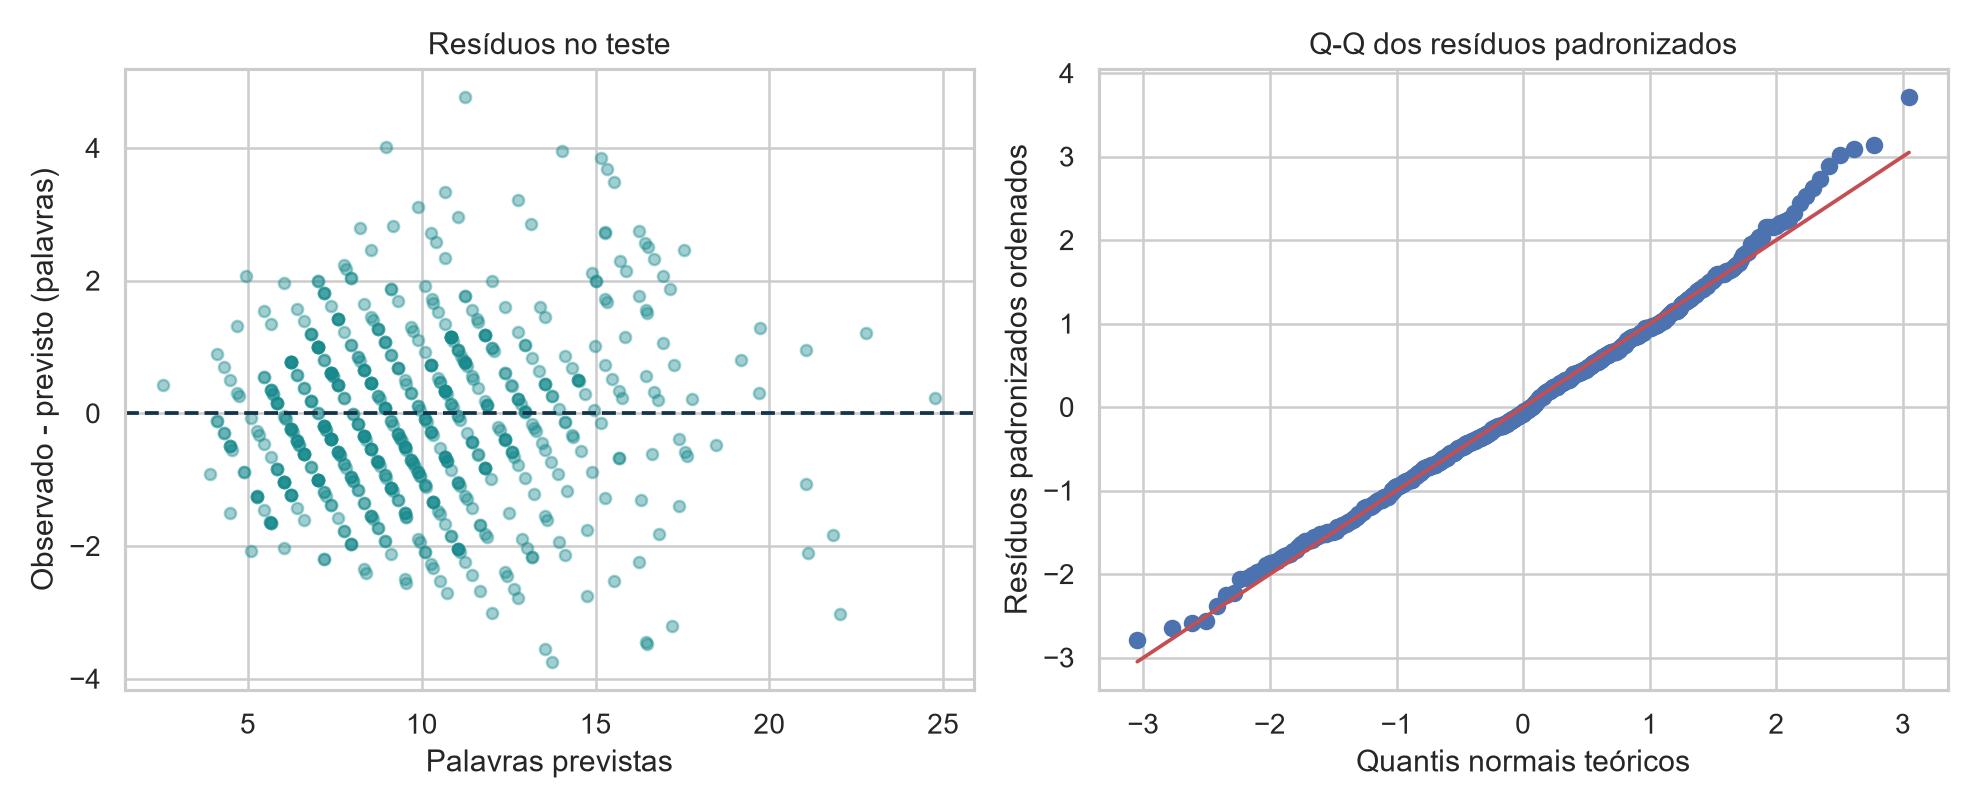

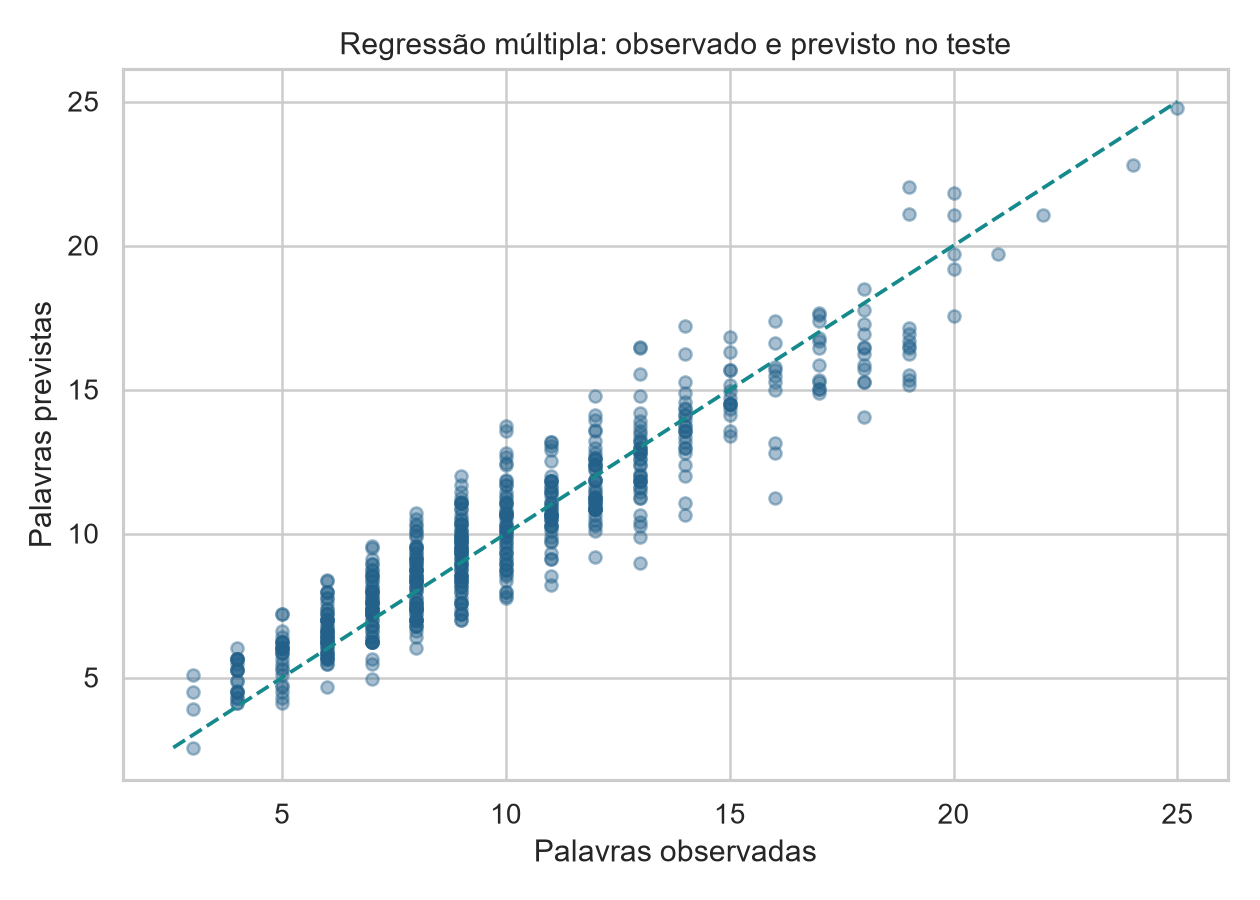

In [5]:
from IPython.display import Image, display
for name in ["01_residual_qq.png", "02_observed_predicted.png"]:
    display(Image(filename=str(OUT / "figures" / name)))